In [3]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

import config

engine = create_engine(
    URL.create(
        "postgresql+psycopg",
        username=config.DB_USER,
        password=config.DB_PASSWORD,
        host=config.DB_HOST,
        port=config.DB_PORT,
        database=config.DB_NAME,
    )
)


def consultar(sql):
    """Roda uma consulta e devolve um DataFrame."""
    return pd.read_sql(sql, engine)


def grafico_barras(df, categoria, valor, titulo, rotulo_categoria, rotulo_valor):
    """Barras horizontais com título, eixos nomeados e legenda."""
    dados = df.copy()
    dados[valor] = dados[valor].astype(float)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(dados[categoria].astype(str), dados[valor], label=rotulo_valor)
    ax.invert_yaxis()
    ax.set_title(titulo)
    ax.set_xlabel(rotulo_valor)
    ax.set_ylabel(rotulo_categoria)
    ax.legend()
    plt.tight_layout()
    plt.show()

### Pergunta : Viagem de maior duração

,id_viagem,nome_orgao_superior,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,Ministério da Previdência Social,2025-01-13,2026-01-31,383,0.00
1,0000000000020793594,Ministério da Justiça e Segurança Pública,2025-01-02,2026-01-15,378,120650.00
2,0000000000020793492,Ministério da Justiça e Segurança Pública,2025-01-11,2026-01-15,369,113382.50
3,0000000000020774569,Ministério da Educação,2025-02-26,2026-03-02,369,0.00
4,0000000000020592696,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,366,159044.90
5,0000000000020685666,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,366,124312.50
6,0000000000020589962,Ministério da Educação,2025-02-23,2026-02-23,365,0.00
7,0000000000020732132,Ministério da Educação,2025-03-31,2026-03-31,365,0.00
8,0000000000020557147,Ministério da Justiça e Segurança Pública,2025-01-01,2025-12-31,364,216729.36
9,0000000000020649880,Ministério da Justiça e Segurança Pública,2025-01-01,2025-12-31,364,207220.14


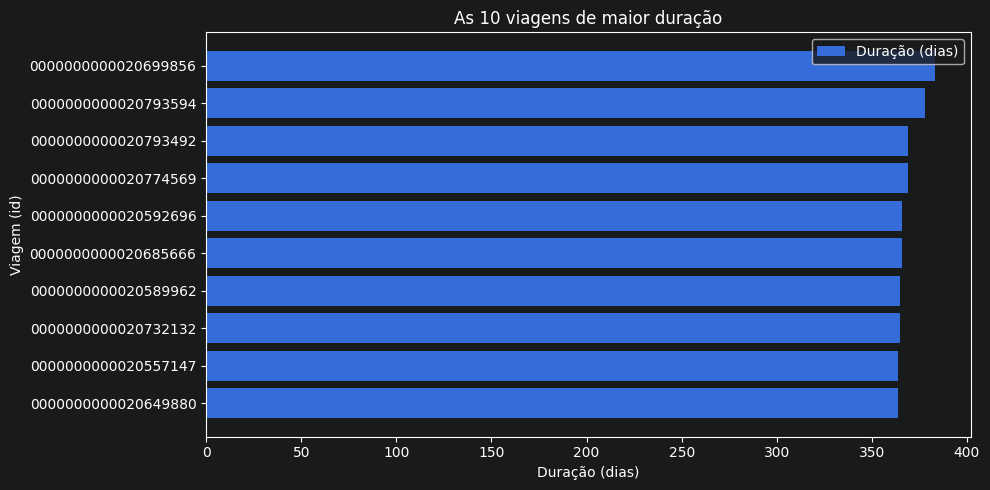

In [4]:
sql_q3 = """
SELECT id_viagem, nome_orgao_superior, data_inicio, data_fim,
       duracao_dias, valor_total
FROM silver_viagem
WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC, valor_total DESC
LIMIT 10
"""
q3 = consultar(sql_q3)
display(q3)
grafico_barras(q3, "id_viagem", "duracao_dias",
               "As 10 viagens de maior duração",
               "Viagem (id)", "Duração (dias)")

### Pergunta: Meio de transporte mais usado nos trechos

,meio_transporte,qtd_trechos
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


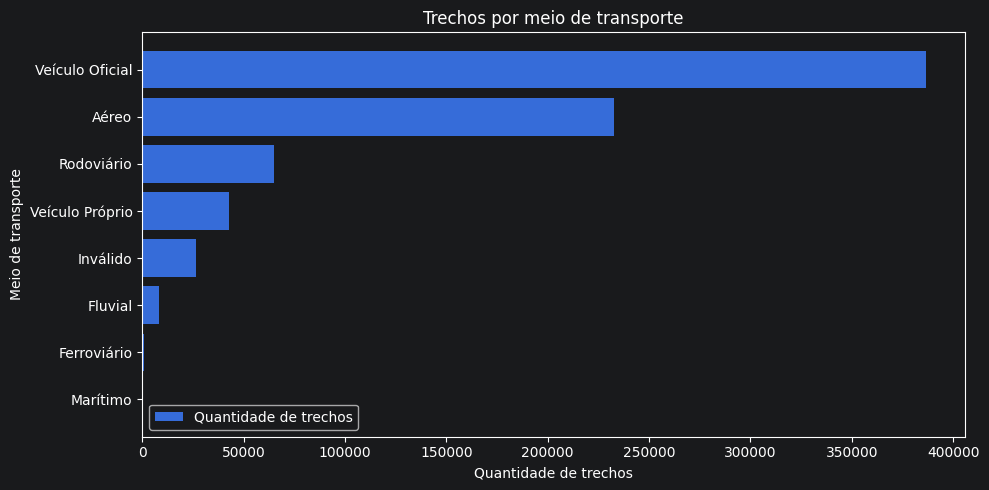

In [5]:
sql_q5 = """
SELECT meio_transporte, COUNT(*) AS qtd_trechos
FROM silver_trecho
WHERE meio_transporte IS NOT NULL
GROUP BY meio_transporte
ORDER BY qtd_trechos DESC
"""
q5 = consultar(sql_q5)
display(q5)
grafico_barras(q5, "meio_transporte", "qtd_trechos",
               "Trechos por meio de transporte",
               "Meio de transporte", "Quantidade de trechos")

### Pergunta: UF de destino mais frequente

,destino_uf,qtd_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603
5,Pará,40044
6,Rio Grande do Sul,38684
7,Mato Grosso do Sul,30516
8,Bahia,28375
9,Pernambuco,28372


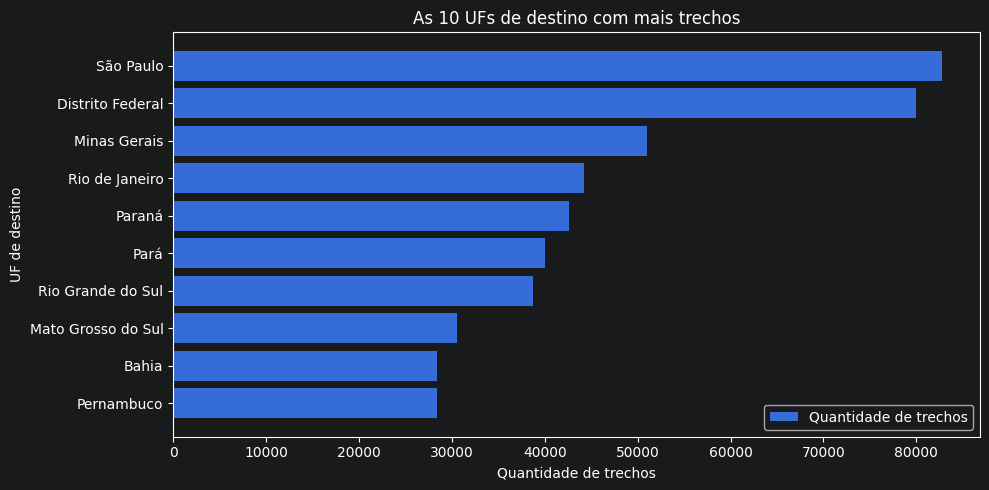

In [6]:
sql_q6 = """
SELECT destino_uf, COUNT(*) AS qtd_trechos
FROM silver_trecho
WHERE destino_uf IS NOT NULL
GROUP BY destino_uf
ORDER BY qtd_trechos DESC
LIMIT 10
"""
q6 = consultar(sql_q6)
display(q6)
grafico_barras(q6, "destino_uf", "qtd_trechos",
               "As 10 UFs de destino com mais trechos",
               "UF de destino", "Quantidade de trechos")